<a href="https://colab.research.google.com/github/nurfahdilla293/praktikum_evaluasi_model.ipynb/blob/main/Latihan_bab_6_knn_naive_bayes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Praktikum Bab 6: KNN dan Naive Bayes
Modul Machine Learning, 6.16 Implementasi Python dan 6.17 Latihan Praktikum

## Praktikum 6.1 Persiapan Library

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score

## Praktikum 6.2 Import Dataset

In [2]:
data = load_wine(as_frame=True)
X, y = data.data, data.target
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print("Ukuran train:", X_train.shape, "| Ukuran test:", X_test.shape)
X.head()

Ukuran train: (142, 13) | Ukuran test: (36, 13)


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


## Praktikum 6.3 Preprocessing (Scaling untuk KNN)

In [20]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


## Praktikum 6.4 Training Model

In [4]:
knn = KNeighborsClassifier(n_neighbors=5, weights="distance")
knn.fit(X_train_scaled, y_train)

nb = GaussianNB()
nb.fit(X_train, y_train)

GaussianNB()

## Praktikum 6.5 Evaluasi

In [5]:
acc_knn = accuracy_score(y_test, knn.predict(X_test_scaled))
acc_nb = accuracy_score(y_test, nb.predict(X_test))
print(f"Akurasi KNN (k=5, weighted): {acc_knn:.3f}")
print(f"Akurasi Gaussian Naive Bayes: {acc_nb:.3f}")

Akurasi KNN (k=5, weighted): 0.972
Akurasi Gaussian Naive Bayes: 0.972


## Praktikum 6.6 Visualisasi (Pengaruh Nilai k)

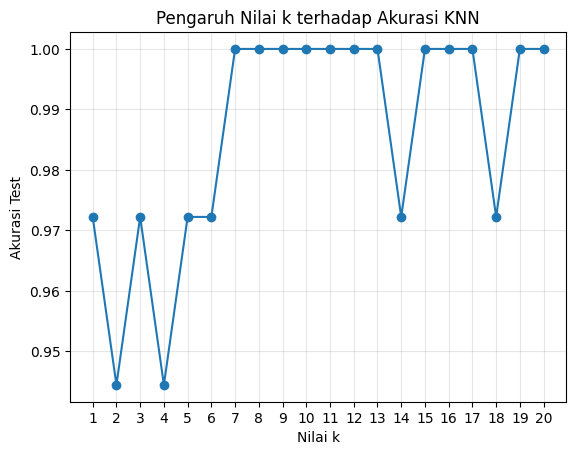

k dengan akurasi test tertinggi: 7 | akurasi: 1.0


In [6]:
akurasi_k = []
nilai_k = range(1, 21)
for k in nilai_k:
    model = KNeighborsClassifier(n_neighbors=k).fit(X_train_scaled, y_train)
    akurasi_k.append(accuracy_score(y_test, model.predict(X_test_scaled)))

plt.plot(nilai_k, akurasi_k, marker='o')
plt.xlabel("Nilai k")
plt.ylabel("Akurasi Test")
plt.title("Pengaruh Nilai k terhadap Akurasi KNN")
plt.xticks(list(nilai_k))
plt.grid(alpha=0.3)
plt.show()

print("k dengan akurasi test tertinggi:", list(nilai_k)[int(np.argmax(akurasi_k))],
      "| akurasi:", round(max(akurasi_k), 4))

### 6.16.1 Interpretasi
Grafik akurasi terhadap nilai k umumnya menunjukkan pola naik-turun: akurasi rendah pada k sangat kecil (overfitting/noise), meningkat pada rentang k menengah, kemudian menurun kembali pada k sangat besar (underfitting). Nilai k optimal biasanya dipilih menggunakan cross-validation, bukan hanya satu kali split train-test.

*Catatan:* pada dataset wine yang kecil dan mudah dipisahkan, kurva bisa cukup datar (akurasi tinggi di banyak nilai k), sehingga pola naik-turunnya tidak selalu tampak jelas.

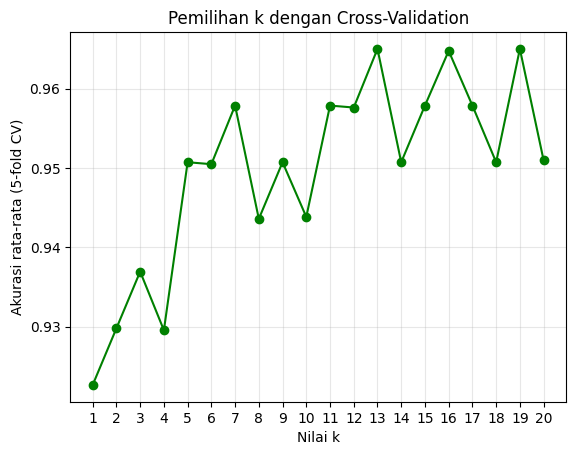

k terbaik berdasarkan CV: 13 | akurasi CV: 0.965


In [7]:
# Tambahan: pemilihan k dengan cross-validation (lebih tepat daripada satu kali split)
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.pipeline import make_pipeline

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = []
for k in nilai_k:
    pipe = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    cv_scores.append(cross_val_score(pipe, X_train, y_train, cv=cv).mean())

plt.plot(nilai_k, cv_scores, marker='o', color="green")
plt.xlabel("Nilai k")
plt.ylabel("Akurasi rata-rata (5-fold CV)")
plt.title("Pemilihan k dengan Cross-Validation")
plt.xticks(list(nilai_k))
plt.grid(alpha=0.3)
plt.show()

print("k terbaik berdasarkan CV:", list(nilai_k)[int(np.argmax(cv_scores))],
      "| akurasi CV:", round(max(cv_scores), 4))

---
## 6.17 Latihan Praktikum
### Praktikum 1: KNN vs Naive Bayes
**Tujuan:** Membandingkan performa KNN dan Naive Bayes pada dataset yang sama.

**Instruksi:** Gunakan dataset `load_breast_cancer`. Latih model KNN (dengan scaling) dan Gaussian Naive Bayes. Bandingkan akurasi, waktu pelatihan, dan waktu prediksi keduanya menggunakan modul `time`.

In [8]:
import time
import pandas as pd
from sklearn.datasets import load_breast_cancer

bc = load_breast_cancer()
Xb, yb = bc.data, bc.target
Xb_train, Xb_test, yb_train, yb_test = train_test_split(
    Xb, yb, test_size=0.2, random_state=42, stratify=yb)

# Scaling untuk KNN (fit hanya pada data training)
sc = StandardScaler()
Xb_train_s = sc.fit_transform(Xb_train)
Xb_test_s = sc.transform(Xb_test)

print("Sampel:", Xb.shape[0], "| Fitur:", Xb.shape[1], "| Kelas:", bc.target_names)
print("Train:", Xb_train.shape, "| Test:", Xb_test.shape)

Sampel: 569 | Fitur: 30 | Kelas: ['malignant' 'benign']
Train: (455, 30) | Test: (114, 30)


In [9]:
N_ULANG = 100   # diulang agar waktu lebih stabil, lalu dirata-rata
hasil = []

konfigurasi = [
    ("KNN (scaled, k=5)", KNeighborsClassifier(n_neighbors=5, weights="distance"), Xb_train_s, Xb_test_s),
    ("Gaussian NB",       GaussianNB(),                                              Xb_train,   Xb_test),
]

for nama, model, Xtr, Xte in konfigurasi:
    waktu_latih, waktu_prediksi = [], []
    for _ in range(N_ULANG):
        t0 = time.perf_counter()
        model.fit(Xtr, yb_train)
        waktu_latih.append(time.perf_counter() - t0)

        t0 = time.perf_counter()
        pred = model.predict(Xte)
        waktu_prediksi.append(time.perf_counter() - t0)

    hasil.append({
        "Model": nama,
        "Akurasi": accuracy_score(yb_test, pred),
        "Waktu Latih (ms)": np.mean(waktu_latih) * 1000,
        "Waktu Prediksi (ms)": np.mean(waktu_prediksi) * 1000,
    })

df_hasil = pd.DataFrame(hasil)
df_hasil.round(4)

,Model,Akurasi,Waktu Latih (ms),Waktu Prediksi (ms)
0,"KNN (scaled, k=5)",0.9561,0.6439,1.6631
1,Gaussian NB,0.9386,1.0482,0.2834


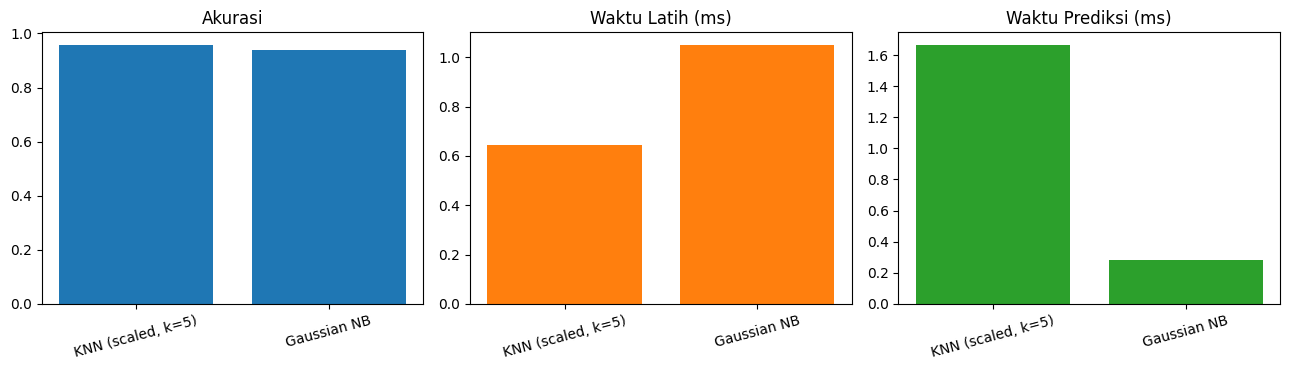

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, kolom, warna in zip(axes, ["Akurasi", "Waktu Latih (ms)", "Waktu Prediksi (ms)"],
                            ["tab:blue", "tab:orange", "tab:green"]):
    ax.bar(df_hasil["Model"], df_hasil[kolom], color=warna)
    ax.set_title(kolom)
    ax.tick_params(axis="x", labelrotation=15)
plt.tight_layout()
plt.show()

**Analisis Praktikum 1** (lengkapi angka sesuai output di Colab-mu):

Dari hasil di Colab-ku, KNN yang di-scaling dapat akurasi sekitar 0,956 dan Gaussian NB sekitar 0,939, jadi KNN sedikit lebih akurat. Waktu latihnya sama-sama cepat banget (KNN sekitar 0,65 ms, NB sekitar 1,05 ms), karena KNN cuma menyimpan data training, sedangkan NB menghitung mean dan varians tiap fitur. Bedanya kelihatan jelas di waktu prediksi, KNN sekitar 1,67 ms dan NB cuma sekitar 0,28 ms, soalnya KNN harus menghitung jarak ke semua data training tiap kali memprediksi. Jadi kalau mau akurasi lebih tinggi, KNN agak unggul, tapi kalau butuh yang cepat dan ringan, NB lebih cocok.

### Praktikum 2: Klasifikasi Teks dengan Multinomial Naive Bayes
**Tujuan:** Menerapkan Multinomial Naive Bayes pada data teks sederhana.

#### Praktikum 6.7 (kode dari modul)

In [19]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB

teks = ["dapatkan diskon gratis sekarang",
        "rapat tim jam 10 pagi",
        "menangkan hadiah gratis klik disini", "laporan keuangan bulan ini","diskon spesial hari ini",
        "jadwal kuliah minggu depan"]
label = [1, 0, 1, 0, 1, 0]

vectorizer = CountVectorizer()
X_teks = vectorizer.fit_transform(teks)
model = MultinomialNB(alpha=1.0)
model.fit(X_teks, label)

teks_baru = ["diskon gratis hari ini"]
prediksi = model.predict(vectorizer.transform(teks_baru))
print("Prediksi:", "Spam" if prediksi[0] == 1 else "Bukan Spam")

Prediksi: Spam


#### Eksplorasi tambahan: representasi Bag-of-Words, probabilitas, dan beberapa teks baru

In [15]:

import pandas as pd
bow = pd.DataFrame(X_teks.toarray(), columns=vectorizer.get_feature_names_out())
bow["label"] = label
bow

,10,bulan,dapatkan,depan,disini,diskon,gratis,hadiah,hari,ini,...,kuliah,laporan,menangkan,minggu,pagi,rapat,sekarang,spesial,tim,label
0,0,0,1,0,0,1,1,0,0,0,...,0,0,0,0,0,0,1,0,0,1
1,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,1,1,0,0,1,0
2,0,0,0,0,1,0,1,1,0,0,...,0,0,1,0,0,0,0,0,0,1
3,0,1,0,0,0,0,0,0,0,1,...,0,1,0,0,0,0,0,0,0,0
4,0,0,0,0,0,1,0,0,1,1,...,0,0,0,0,0,0,0,1,0,1
5,0,0,0,1,0,0,0,0,0,0,...,1,0,0,1,0,0,0,0,0,0


In [16]:

teks_uji = ["diskon gratis hari ini",
            "rapat laporan minggu depan",
            "klik hadiah gratis sekarang",
            "jadwal kuliah hari ini"]

proba = model.predict_proba(vectorizer.transform(teks_uji))
pred = model.predict(vectorizer.transform(teks_uji))

for t, p, pr in zip(teks_uji, pred, proba):
    print(f"{t!r:35} -> {'Spam' if p == 1 else 'Bukan Spam':10} "
          f"(P(bukan spam)={pr[0]:.3f}, P(spam)={pr[1]:.3f})")

'diskon gratis hari ini'            -> Spam       (P(bukan spam)=0.053, P(spam)=0.947)
'rapat laporan minggu depan'        -> Bukan Spam (P(bukan spam)=0.941, P(spam)=0.059)
'klik hadiah gratis sekarang'       -> Spam       (P(bukan spam)=0.040, P(spam)=0.960)
'jadwal kuliah hari ini'            -> Bukan Spam (P(bukan spam)=0.667, P(spam)=0.333)


In [17]:

teks_ambigu = vectorizer.transform(["rapat diskon hari ini"])
for a in [0.01, 0.1, 1.0, 5.0]:
    m = MultinomialNB(alpha=a).fit(X_teks, label)
    print(f"alpha={a:<5} P(spam) = {m.predict_proba(teks_ambigu)[0][1]:.3f}")

alpha=0.01  P(spam) = 0.995
alpha=0.1   P(spam) = 0.955
alpha=1.0   P(spam) = 0.750
alpha=5.0   P(spam) = 0.583


**Hasil Analisis Praktikum 2:**

`CountVectorizer` mengubah teks menjadi vektor jumlah kata (Bag-of-Words) sehingga cocok dipakai untuk Multinomial Naive Bayes, dan teks "diskon gratis hari ini" diprediksi **Spam** karena kata *diskon* dan *gratis* lebih sering muncul pada data spam. Laplace smoothing (`alpha`) mencegah probabilitas nol untuk kata yang tidak pernah muncul pada suatu kelas, dan makin besar alpha, estimasinya makin halus. Namun, data latih yang hanya 6 kalimat membuat model ini sebatas demonstrasi, dan kata baru yang belum pernah dilihat saat training akan diabaikan.